# Capital structure
Set `TICKER` (a `market_cds_ticker`, the `CDS_Ticker` column of `cds_mappings_final.csv`) and run. Pulls the name's debt (bonds, term loans, RCFs) with Bloomberg BQL
through your open Excel (`pricing/shared/bbg_bql.py`) and plots the bond notional by maturity.

**Needs the SYSTEM Python kernel** (xlwings + Excel with the Bloomberg add-in + Terminal logged in), not the project `.venv`. This is the one notebook that is not analysis-only.

In [1]:
TICKER = 'MPW'            # market_cds_ticker
ISSUEDBY = 'CAST_PARENT_SUBS'   # parent + subsidiaries; other BQL values work too
PCT_BASE = 'bonds'         # denominator of the running % due: 'bonds' (chart total, ends at 100%) or 'all' (bonds + term loans + RCFs outstanding)

In [2]:
import sys, pathlib
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'pricing' / 'shared' / 'bbg_bql.py').exists())
sys.path.insert(0, str(ROOT / 'pricing' / 'shared'))
from bbg_bql import debt_for_cds_tickers, equity_ticker

pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.max_rows', 300)
print(f'{TICKER} -> {equity_ticker(TICKER)}')

MPW -> MPT US Equity


In [3]:
raw = debt_for_cds_tickers(TICKER, issuedby=ISSUEDBY)
if raw.empty:
    raise SystemExit(f'no debt returned for {TICKER}')

debt = raw.rename(columns={'amt_outstanding(currency=USD)': 'amt_usd', 'srch_asset_class': 'asset_class', 'amt_outstanding': 'amt_local'}).copy()
rcf = (' ' + debt['name'].str.upper() + ' ').apply(lambda n: any(f' {k} ' in n for k in ('REV', 'RCF', 'RC', 'LC')))      # revolvers / letter-of-credit lines
debt['type'] = 'Bond'
debt.loc[debt.asset_class.eq('Loans'), 'type'] = 'Term loan'
debt.loc[debt.asset_class.eq('Loans') & rcf, 'type'] = 'RCF'

today = pd.Timestamp.today().normalize()
current = debt[debt.maturity.isna() | (debt.maturity >= today)]        # still outstanding (perps have no maturity)
print(f'{len(debt)} instruments returned, {len(current)} current (maturity on/after {today:%Y-%m-%d} or perpetual)')

summary = current.groupby('type').agg(n=('id', 'size'), notional_usd_mm=('amt_usd', lambda s: s.sum() / 1e6))
display(summary.round(1))
display(current.sort_values('maturity', na_position='last')[['type', 'name', 'crncy', 'issue_dt', 'maturity', 'amt_local', 'amt_usd', 'cpn']]
        .assign(amt_usd=lambda d: (d.amt_usd / 1e6).round(1), amt_local=lambda d: (d.amt_local / 1e6).round(1)).rename(columns={'amt_usd': 'amt_usd_mm', 'amt_local': 'amt_local_mm'}).reset_index(drop=True))

attaching to Excel pid 37548


14 instruments returned, 14 current (maturity on/after 2026-11-04 or perpetual)


,n,notional_usd_mm
type,,
Bond,8,8146.1
RCF,2,718.6
Term loan,4,2581.6


,type,name,crncy,issue_dt,maturity,amt_local_mm,amt_usd_mm,cpn
0,RCF,MPW REV GUAR USD Corp,USD,2014-06-19,2027-05-06,718.6,718.6,6.2799
1,Term loan,MPW TL A GUAR USD Corp,USD,2022-06-29,2027-06-30,200.0,200.0,6.2828
2,Bond,MPW 5 10/15/27,USD,2017-09-21,2027-10-15,665.4,665.4,5.0000
3,Bond,MPW 3.692 06/05/28,GBP,2019-12-05,2028-06-05,600.0,789.5,3.6920
4,RCF,MPTUTP LC 1L USD Corp,USD,2024-04-12,2029-04-12,NaN,NaN,NaN
5,Term loan,MPTUTP TL 1L USD Corp,USD,2024-04-12,2029-04-12,770.0,770.0,NaN
6,Bond,MPW 4 ⅝ 08/01/29,USD,2019-07-26,2029-08-01,581.2,581.2,4.6250
7,Bond,MPW 3 ⅜ 04/24/30,GBP,2021-03-24,2030-04-24,350.0,480.0,3.3750
8,Bond,MPW 3 ½ 03/15/31,USD,2020-12-04,2031-03-15,687.5,687.5,3.5000
9,Bond,MPW 7 02/15/32,EUR,2025-02-13,2032-02-15,1000.0,1042.6,7.0000


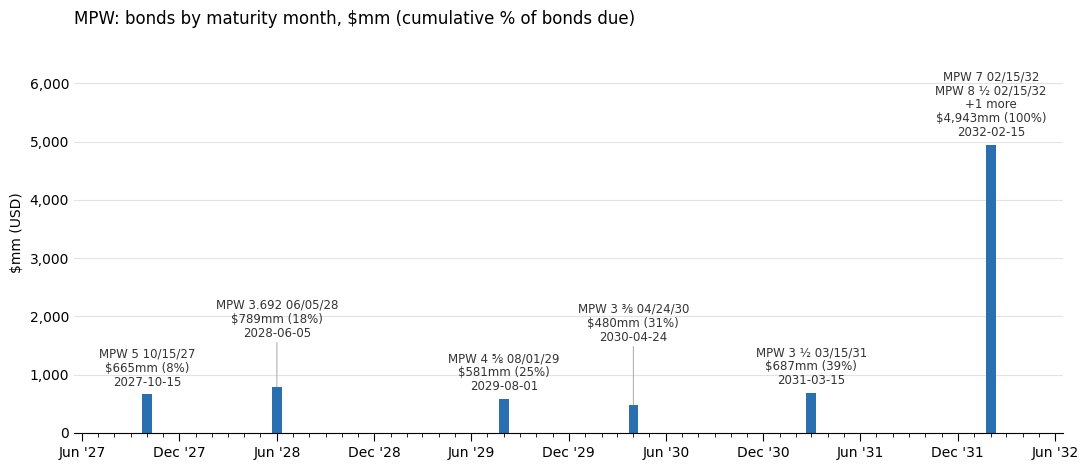

total bonds shown: USD 8,146 mm


,securities,usd_mm,cum_usd_mm,cum_pct
2027-10,MPW 5 10/15/27,665.396,665.396,8.2
2028-06,MPW 3.692 06/05/28,789.480,1454.876,17.9
2029-08,MPW 4 ⅝ 08/01/29,581.229,2036.105,25.0
2030-04,MPW 3 ⅜ 04/24/30,479.955,2516.060,30.9
2031-03,MPW 3 ½ 03/15/31,687.488,3203.548,39.3
2032-02,MPW 7 02/15/32; MPW 8 ½ 02/15/32; MPW 9 ¼ 02/1...,4942.600,8146.148,100.0


In [4]:
import matplotlib.dates as mdates

bonds = current[(current.type == 'Bond') & current.maturity.notna() & current.amt_usd.notna()]
by_month = (bonds.assign(month=bonds.maturity.dt.to_period('M')).groupby('month').amt_usd.sum() / 1e6)
by_month = by_month.reindex(pd.period_range(by_month.index.min(), by_month.index.max(), freq='M'), fill_value=0)     # every month on the axis, so spacing is true
base = by_month.sum() if PCT_BASE == 'bonds' else current.amt_usd.sum() / 1e6
cum = by_month.cumsum() / base                                                                                      # running share of the debt that has come due by the end of each month
x = by_month.index.to_timestamp()                                                                                    # bar centred on the 1st of its month

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(x, by_month.values, width=18, color='#2a6fb0')                                                                # thin bins (days)
ax.set_title(f'{TICKER}: bonds by maturity month, $mm (cumulative % of {"bonds" if PCT_BASE == "bonds" else "all debt"} due)', loc='left', fontsize=12)
ax.set_ylabel('$mm (USD)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

# x axis: a tick for every monthly bin, a label every 6 months (Jun '27, Dec '27, ...); every 12 months when the range is long enough that 6-month labels would collide
span_months = len(by_month)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[6, 12] if span_months <= 84 else [6]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
first, last = by_month.index[0].to_timestamp(), by_month.index[-1].to_timestamp()
lo = pd.Timestamp(first.year if first.month >= 6 else first.year - 1, 6 if first.month >= 6 else 12, 1)           # pad to a labelled tick either side
hi = pd.Timestamp(last.year if last.month <= 6 else last.year + 1, 6 if last.month <= 6 else 12, 1)
ax.set_xlim(lo - pd.Timedelta(days=15), hi + pd.Timedelta(days=15))
ax.grid(axis='y', color='#e3e3e3', linewidth=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3)

# labels: horizontal "$665mm (8%)" with the exact maturity date(s) below, above each bar. Packed in 2-D against the other labels AND the bars so nothing overlaps;
# a label pushed up off its bar gets a thin leader line
names_by_month = bonds.assign(month=bonds.maturity.dt.to_period('M')).groupby('month').name.agg(lambda n: list(n))
dates_by_month = bonds.assign(month=bonds.maturity.dt.to_period('M')).groupby('month').maturity.agg(lambda d: sorted(set(d.dt.strftime('%Y-%m-%d'))))
fig.canvas.draw()
axis_px, axis_pt = ax.get_window_extent().width, ax.get_window_extent().height * 72 / fig.dpi
days_per_px = (ax.get_xlim()[1] - ax.get_xlim()[0]) / axis_px
FONT, STEP, BASE = 8.5, 5, 4                                                                    # font pt, row step pt, gap above the bar pt
px_per_char = FONT * fig.dpi / 72 * 0.6
items = []
for per, v, c in zip(by_month.index, by_month.values, cum.values):
    if not v:
        continue
    nm = names_by_month[per]
    nm = nm if len(nm) <= 2 else nm[:2] + [f'+{len(nm) - 2} more']                                  # security name(s) above the amount
    lines = nm + [f'${v:,.0f}mm ({c:.0%})' if v >= 10 else f'${v:,.1f}mm ({c:.0%})'] + dates_by_month[per]
    xi = mdates.date2num(per.to_timestamp())
    half = (max(len(l) for l in lines) * px_per_char / 2 + 2) * days_per_px                      # half label width in days (+2 px gap)
    items.append((xi, v, chr(10).join(lines), half, len(lines) * FONT * 1.25 + 2))                 # label height in pt
bar_half = 9.5                                                                                  # half bar width in days (+ margin)

def pack(ytop):
    scale = axis_pt / ytop                                                                      # pt per $mm
    bars = [(xi - bar_half, xi + bar_half, 0, v * scale) for xi, v, *_ in items]
    placed, rects, top = [], [], 0
    for xi, v, text, half, h in items:
        y0 = v * scale + BASE
        while any(xi - half < x1 and xi + half > x0 and y0 < yb1 and y0 + h > yb0 for x0, x1, yb0, yb1 in bars + rects):
            y0 += STEP
        rects.append((xi - half, xi + half, y0, y0 + h)); placed.append((xi, v, text, y0 - v * scale)); top = max(top, y0 + h)
    return placed, top, scale

ytop = max(v for _, v, *_ in items) * 1.15
for _ in range(12):                                                                             # grow the y axis until the highest label fits
    placed, top, scale = pack(ytop)
    if top <= axis_pt:
        break
    ytop *= 1.1
ax.set_ylim(0, ytop)
for xi, v, text, off in placed:
    ax.annotate(text, xy=(xi, v), xytext=(0, off), textcoords='offset points', ha='center', va='bottom', fontsize=FONT, color='#333', linespacing=1.1,
                arrowprops=dict(arrowstyle='-', lw=0.6, color='#999', shrinkA=0, shrinkB=0) if off > BASE + 1 else None)
excluded = current[(current.type == 'Bond') & ~current.index.isin(bonds.index)]
if len(excluded):
    ax.annotate(f'{len(excluded)} bond(s) not shown (perpetual or no amount)', xy=(0, -0.14), xycoords='axes fraction', fontsize=8, color='#666')
plt.tight_layout(); plt.show()
print(f'total bonds shown: USD {by_month.sum():,.0f} mm')
display(pd.DataFrame({'securities': names_by_month.reindex(by_month.index).map(lambda n: '; '.join(n) if isinstance(n, list) else ''), 'usd_mm': by_month, 'cum_usd_mm': by_month.cumsum(), 'cum_pct': (cum * 100).round(1)})[by_month > 0])